<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Gradient Descent, SGD, Momentum and Adam Comparison

**Category**: CO1 – Mathematical Foundations and Optimization  
**Objective**: Implement and compare convergence trajectories of Gradient Descent, Momentum, and Adam optimizers on non-isotropic loss surfaces.


### Task 1: Define 2D Optimization Objective and Custom Optimizers


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Quadratic bowl loss: f(x, y) = 0.5 * (x^2 + 8 * y^2)
def loss_func(w):
    return 0.5 * (w[0]**2 + 8.0 * w[1]**2)

def grad_func(w):
    return np.array([w[0], 8.0 * w[1]])

# Implement pure NumPy optimizers
def run_gd(w_init, lr=0.18, steps=35):
    traj = [w_init.copy()]
    w = w_init.copy()
    for _ in range(steps):
        w -= lr * grad_func(w)
        traj.append(w.copy())
    return np.array(traj)

def run_momentum(w_init, lr=0.18, beta=0.85, steps=35):
    traj = [w_init.copy()]
    w = w_init.copy()
    v = np.zeros_like(w)
    for _ in range(steps):
        v = beta * v + (1 - beta) * grad_func(w)
        w -= lr * v
        traj.append(w.copy())
    return np.array(traj)

def run_adam(w_init, lr=0.45, beta1=0.9, beta2=0.999, eps=1e-8, steps=35):
    traj = [w_init.copy()]
    w = w_init.copy()
    m = np.zeros_like(w)
    v = np.zeros_like(w)
    for t in range(1, steps + 1):
        g = grad_func(w)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * (g ** 2)
        m_hat = m / (1 - beta1 ** t)
        v_hat = v / (1 - beta2 ** t)
        w -= lr * m_hat / (np.sqrt(v_hat) + eps)
        traj.append(w.copy())
    return np.array(traj)

start_point = np.array([-4.5, 2.5])
traj_gd = run_gd(start_point)
traj_mom = run_momentum(start_point)
traj_adam = run_adam(start_point)

print(f"Final Position GD: {np.round(traj_gd[-1], 4)}, Loss: {loss_func(traj_gd[-1]):.6f}")
print(f"Final Position Momentum: {np.round(traj_mom[-1], 4)}, Loss: {loss_func(traj_mom[-1]):.6f}")
print(f"Final Position Adam: {np.round(traj_adam[-1], 4)}, Loss: {loss_func(traj_adam[-1]):.6f}")


Final Position GD: [-0.0043 -0.    ], Loss: 0.000009
Final Position Momentum: [-0.0415 -0.0485], Loss: 0.010255
Final Position Adam: [-0.3386 -0.1189], Loss: 0.113907


### Task 2: Visualize Trajectories on 2D Loss Contours


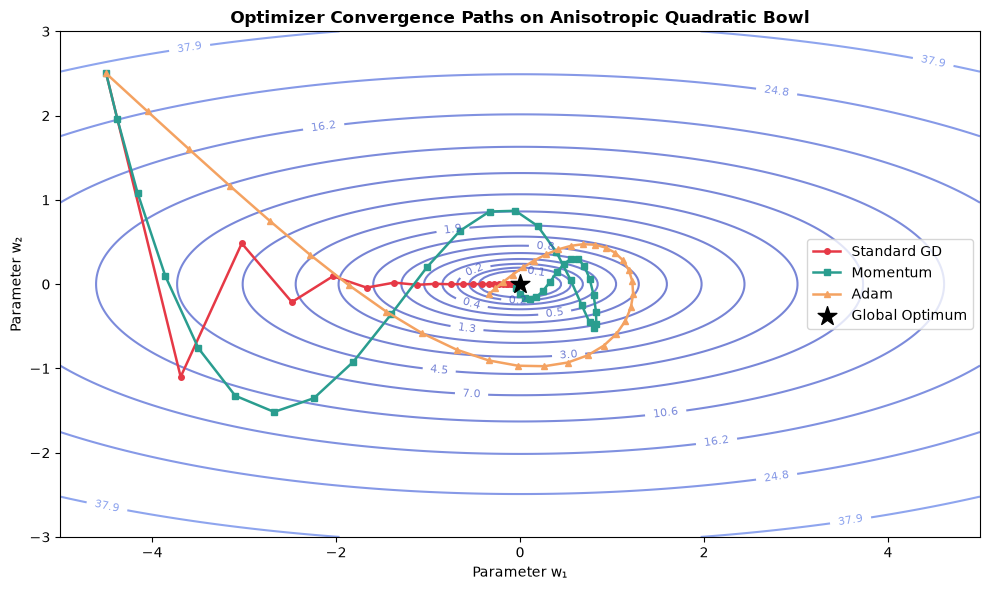

In [2]:
x_vals = np.linspace(-5, 5, 200)
y_vals = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x_vals, y_vals)
Z = 0.5 * (X**2 + 8.0 * Y**2)

plt.figure(figsize=(10, 6))
cp = plt.contour(X, Y, Z, levels=np.logspace(-1, 2.5, 20), cmap='coolwarm', alpha=0.7)
plt.clabel(cp, inline=True, fontsize=8)

plt.plot(traj_gd[:, 0], traj_gd[:, 1], color='#e63946', marker='o', markersize=4, lw=1.8, label='Standard GD')
plt.plot(traj_mom[:, 0], traj_mom[:, 1], color='#2a9d8f', marker='s', markersize=4, lw=1.8, label='Momentum')
plt.plot(traj_adam[:, 0], traj_adam[:, 1], color='#f4a261', marker='^', markersize=4, lw=1.8, label='Adam')

plt.scatter([0], [0], color='black', marker='*', s=200, zorder=10, label='Global Optimum')
plt.title("Optimizer Convergence Paths on Anisotropic Quadratic Bowl", fontweight='bold')
plt.xlabel("Parameter w₁")
plt.ylabel("Parameter w₂")
plt.legend()
plt.tight_layout()
plt.show()


### Task 3: Convergence Loss vs. Iterations


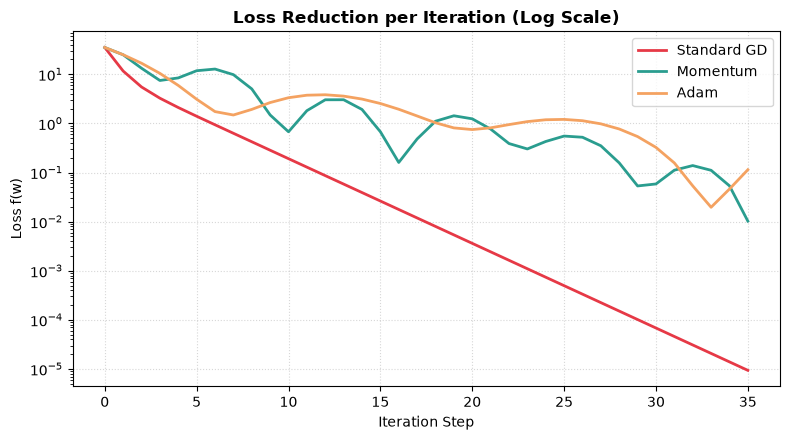

In [3]:
losses_gd = [loss_func(pt) for pt in traj_gd]
losses_mom = [loss_func(pt) for pt in traj_mom]
losses_adam = [loss_func(pt) for pt in traj_adam]

plt.figure(figsize=(8, 4.5))
plt.plot(losses_gd, color='#e63946', lw=2, label='Standard GD')
plt.plot(losses_mom, color='#2a9d8f', lw=2, label='Momentum')
plt.plot(losses_adam, color='#f4a261', lw=2, label='Adam')
plt.yscale('log')
plt.title("Loss Reduction per Iteration (Log Scale)", fontweight='bold')
plt.xlabel("Iteration Step")
plt.ylabel("Loss f(w)")
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
